# Weighted Coverage Method

Here, we weight some of the regions to have higher importance as compared to others based on the rated value  

In [1]:
import Pkg; Pkg.activate("../.."); Pkg.instantiate()

  Activating project at `~/Kaleb_Data/PhD_Research/CPS_Project/adaptive-ocean-exploration-sim`


In [2]:
using Logging: global_logger
using TerminalLoggers: TerminalLogger
global_logger(TerminalLogger())

using ProgressLogging

In [3]:
using Plots, Revise, StaticArrays, Interpolations, LinearAlgebra, LazySets

In [4]:
include("../../src/kf.jl")
include("../../src/ngpkf.jl")
include("../../src/SyntheticData.jl")
include("../../src/ergodic.jl")
include("../../src/simulator_spatial.jl")
include("../../src/Convex_bound_avoidance.jl")

Main.ConvexBoundAvoidance

## Spatial-only Matern-12 Kernel

In [10]:
# Define domain vars
dim = 100; # number of data points along each axis in the domain (defining a square domain)
xstart, xstop = 0, 1.4; # x-axis start and end positions
ystart, ystop = 0, 6.5; # y-axis start and end positions

σ_sq = 1.0
λₓ = 1/(5.0) 

env_data = SyntheticData.matern12_spatial(dim, xstart, xstop, ystart, ystop, σ_sq, λₓ);
# heatmap(range(xstart, stop=xstop, length=dim), range(ystart, stop=ystop, length=dim), env_data; c = :vik)
# title!("Synthetic Data: σ² = $(σ_sq), λₓ = $(λₓ)")

In [11]:
plotly();
heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
# plot!(clims=(-2,2))

In [12]:
# Create an ngpkf grid based on the data

σ_spatial = σ_sq
# l_spatial = 1/λₓ_wrong
l_spatial = 1/λₓ

res_factor = 0.1 #l_spatial / sqrt(2.0)

kern = NGPKF.MaternKernel(σ_spatial, l_spatial)

ngp_grid_x = range(extrema(env_data.X)..., step= res_factor )
ngp_grid_y = range(extrema(env_data.Y)..., step= res_factor )


0.0:0.1:6.5

In [13]:
kern

Main.NGPKF.MaternKernel{Float64}(1.0, 5.0)

In [14]:
ngpkf_grid = NGPKF.NGPKFGrid(ngp_grid_x, ngp_grid_y, kern)

Main.NGPKF.NGPKFGrid{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{SVector{2, Float64}}, Hermitian{Float64, Matrix{Float64}}, Main.NGPKF.MaternKernel{Float64}}(0.0:0.1:1.4, 0.0:0.1:6.5, SVector{2, Float64}[[0.0, 0.0], [0.1, 0.0], [0.2, 0.0], [0.3, 0.0], [0.4, 0.0], [0.5, 0.0], [0.6, 0.0], [0.7, 0.0], [0.8, 0.0], [0.9, 0.0]  …  [0.5, 6.5], [0.6, 6.5], [0.7, 6.5], [0.8, 6.5], [0.9, 6.5], [1.0, 6.5], [1.1, 6.5], [1.2, 6.5], [1.3, 6.5], [1.4, 6.5]], Main.NGPKF.MaternKernel{Float64}(1.0, 5.0), [40.08069042734174 -21.541322722682967 … 0.0002121159172414541 0.0031679467448675813; -21.541322722682967 56.189078056678945 … 2.4879701597056412e-5 0.00021211591720154418; … ; 0.0002121159172414541 2.4879701597056412e-5 … 56.18907805667934 -21.541322722683297; 0.0031679467448675813 0.00021211591720154418 … -21.541322722683297 40.0806904273421])

In [15]:
size(ngp_grid_x), size(ngp_grid_y)

((15,), (66,))

In [16]:
# x0s = [@SVector[rand(ngpkf_grid.xs[2:(end-2)]), rand(ngpkf_grid.ys[2:(end-2)])] for i=1:1]
x0s = [@SVector[0.75, 3.0] for i=1:1]

1-element Vector{SVector{2, Float64}}:
 [0.75, 3.0]

In [17]:
SimulatorSpatial.measure(0.0, x0s, env_data; σ_meas = 0.05)

1-element Vector{Main.SimulatorSpatial.MeasurementSpatial{Float64, SVector{2, Float64}, Float64}}:
 Main.SimulatorSpatial.MeasurementSpatial{Float64, SVector{2, Float64}, Float64}(0.0, [0.75, 3.0], 2.1217311769503118)

In [18]:
plot()
heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
scatter!(first.(x0s), last.(x0s), label = "")
title!("q_T= 0.95 for w_T = 1.5 | Rest = 0.0")
# plot!(clims=(-2,2))

In [19]:
# Define the Jordan lake domain

VP_Polygon = VPolygon([[0.4, 0],
    [0.7362, 0],
    [1.1925, 4.3707],
    [1.3366, 6.3399],
    [0.2559, 4.7069],
    [0.0398, 1.3929],
])

vertices = [0.4 0.7362 1.1925 1.3366 0.2559 0.0398;
            0 0 4.3707 6.3399 4.7069 1.3929]


# Create a ConvexPolygon object
convex_polygon = ConvexBoundAvoidance.ConvexPolygon(VP_Polygon, vertices)
convex_polygon.edges

2×6 Matrix{Float64}:
 -0.3362  -0.4563  -0.1441  1.0807  0.2161  -0.3602
  0.0     -4.3707  -1.9692  1.633   3.314    1.3929

In [20]:
plot()
heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
scatter!(first.(x0s), last.(x0s), label = "")
polygon_vertices = hcat(convex_polygon.vertices, convex_polygon.vertices[:, 1])  # Close the polygon
plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.2, label="")
xlims!(0,1.4)
ylims!(0,6.5)

In [21]:
function Cfun(p, x)
    return kern(x, p)^2 / kern(p, p)
end
function Rfun(p, x)
    return (kern(x,x) - kern(x, p)^2 / kern(p, p) + 0.5^2)/(ΔT)
end


S(p, x)  = Cfun(p, x)^2 / Rfun(p, x)
DxS(p, x) = ForwardDiff.gradient(xx-> S(p, xx), x)

DxS (generic function with 1 method)

In [27]:
Cfun(2,2)
Rfun(0, 0)

6.0

In [28]:
using DifferentialEquations
using ForwardDiff

function clarity_prediction(t, q0, C, R, Q)

    k = C / sqrt(Q * R)
    
    q∞ = k / (1 + k)

    γ1 = q∞ - q0
    γ2 = γ1 * (k-1)
    γ3 = (k-1) * q0 - k

    return q∞ * ( 1 + 2 * γ1 / (γ2 + γ3 * exp(2 * k * Q * t)))
end

    
function clarity_time(q0, qf, C, R, Q; tmax=10.0)
    
    println("q0: $(q0)")
    println("qf: $(qf)")
    println("C: $(C)")
    println("R: $(R)")
    println("Q: $(Q)")
    
    if q0 >= qf
        return 0.0
    end

    k = C / sqrt(Q * R)
    println("k: $(k)")
    
    q∞ = k / (1 + k)
    println("q∞: $(q∞)")
    γ1 = q∞ - q0
    γ2 = γ1 * (k-1)
    γ3 = (k-1) * q0 - k

    
        
    if qf >= q∞
        return tmax
    end

    t = log((2*q∞*γ1 - qf*γ2 + q∞*γ2)/((qf - q∞)*γ3))/(2*k*Q)
    println("t: $(t)")

    return min(t, tmax)
end


C_ = Cfun(0,0)
R_ = Rfun(0,0)

k = (C_^2 / R_)
# q(t) = ((-k * t * q_0) + (k * t * q_0)) / ((-k * t * q_0) + (k * t) + 1)

function Clarity_delta_t(current_clarity, target_clarity)
    delta_t = (target_clarity - current_clarity) / ((target_clarity - 1) * k * (current_clarity - 1))
    return delta_t
end

function Clarity_delta_new(current_clarity, target_clarity)
    den = -target_clarity*k + k*current_clarity*target_clarity + k - k*current_clarity
    return delta_t = (target_clarity - current_clarity) / den
end


Clarity_delta_new (generic function with 1 method)

In [29]:
# Controller for weighted 2
using LinearAlgebra, StatsBase

function ergo_controller_weighted_2(t, xs, Mean, w_rated_val, convex_polygon;
        ergo_grid,
        ergo_q_map,
        traj,
        umax= 0.15, #30.0 * 60 / 1000,
        ΔT,
        kwargs...
        )
        
    target_q = 0.95

    # Set the rated value matrix    
    Nx, Ny = length(ngpkf_grid.xs), length(ngpkf_grid.ys)
    w_rated = ones(Nx, Ny)
    w_rated *= w_rated_val
  
#   Compute the target matrix 
    lambda_param = 0.05
    delta = -lambda_param*((Mean - w_rated).^2)
    q_target_temp = target_q*(exp.(delta)) 
    
    
    # Mask the matrix such that q_target is zero outisde the domain
    x_domain = range(0, 1.4, length=Nx)
    y_domain = range(0, 6.5, length=Ny)

    for i in 1:length(x_domain)
        for j in 1:length(y_domain)
            p = [x_domain[i], y_domain[j]]
            if (p ∈ convex_polygon.polygon) == false
                q_target_temp[i, j] = 0.0
            end
        end
    end

    # Get it in the right shape
    q_target_itp = linear_interpolation((ngpkf_grid.xs, ngpkf_grid.ys), q_target_temp, extrapolation_bc=Interpolations.Line())
    q_target_weighted = q_target_itp(ErgodicController.xs(ergo_grid), ErgodicController.ys(ergo_grid))     

    
    target_spatial_dist = zeros(size(ergo_q_map))
    Qp  = mean(σ_t.^2) # diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT ))      
    
    for i in CartesianIndices(target_spatial_dist)
        if q_target_weighted[i] > ergo_q_map[i]
#             println("here in first cond")
            target_spatial_dist[i] = Clarity_delta_new(ergo_q_map[i], q_target_weighted[i])
        else
            target_spatial_dist[i] = 0.0
        end
    end
        
    u = [ErgodicController.controller_single_integrator_cvx_bound(ergo_grid, x, traj, target_spatial_dist, convex_polygon; umax=umax, do_boundary_correction=true) for x in xs]
    
#     println(u)
    
    return u, q_target_temp

end

ergo_controllers_weighted_2 = [ergo_controller_weighted_2 for i=1:length(x0s)]

1-element Vector{typeof(ergo_controller_weighted_2)}:
 ergo_controller_weighted_2 (generic function with 1 method)

In [82]:
# Frequencies
# Control input: Every 5 seconds
# Fusing Measurements: Every 300 seconds

ΔT = 5.0/120.0 # minutes
Tend = 0.1 # hours 
ts = 0.0:(ΔT):(300)
fuse_measurements_every_ΔT = 5.0 # minutes
recompute_controller_every_ΔT = 5.0 / 60.0 # minutes i.e. every 5 seconds 
σ_t = zeros(66, 15);

In [83]:
w_rated_val = 3
@time res_ergo_exp =  SimulatorSpatial.simulate_weighted_exp_spatial_cvx_bound(ts, x0s, ergo_controller_weighted_2, w_rated_val, convex_polygon; 
    ngpkf_grid=ngpkf_grid, 
    EnvDataSpatial=env_data, 
    σ_meas = 0.5,
    # σ_process= 0.075 * fuse_measurements_every_ΔT,
    Q_process = diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT )) , 
    fuse_measurements_every_ΔT = fuse_measurements_every_ΔT, 
    recompute_controller_every_ΔT = recompute_controller_every_ΔT)

Progress:   0%|                                         |  ETA: N/A
Progress:   1%|▎                                        |  ETA: 0:01:49
Progress:   1%|▍                                        |  ETA: 0:01:53
Progress:   2%|▋                                        |  ETA: 0:01:51


Inside prediction of NGP


Progress:   2%|▉                                        |  ETA: 0:01:57
Progress:   3%|█                                        |  ETA: 0:01:55
Progress:   3%|█▎                                       |  ETA: 0:01:53


Inside prediction of NGP


Progress:   4%|█▌                                       |  ETA: 0:01:54
Progress:   4%|█▋                                       |  ETA: 0:01:53
Progress:   5%|█▉                                       |  ETA: 0:01:52


...

Inside prediction of NGP


Progress:  99%|████████████████████████████████████████▌|  ETA: 0:00:01
Progress:  99%|████████████████████████████████████████▋|  ETA: 0:00:01
Progress: 100%|████████████████████████████████████████▉|  ETA: 0:00:00


 90.183847 seconds (2.47 G allocations: 90.184 GiB, 5.10% gc time)


Progress: 100%|█████████████████████████████████████████| Time: 0:01:30


Main.SimulatorSpatial.SimResultWeighted{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{Vector{SVector{2, Float64}}}, Vector{Vector{SVector{2, Float64}}}, Vector{Main.SimulatorSpatial.MeasurementSpatial{Float64, SVector{2, Float64}, Float64}}, Vector{Float64}, Vector{Main.KF.KFState{Vector{Float64}, UpperTriangular{Float64, Matrix{Float64}}}}, Vector{Matrix{Float64}}}(0.0:0.041666666666666664:300.0, Vector{SVector{2, Float64}}[[[0.75, 3.0]], [[0.7534053935473399, 3.00524078188706]], [[0.7558414444247998, 3.0109964882835354]], [[0.7603241051896283, 3.01535174401282]], [[0.7654708947450207, 3.018897594724921]], [[0.7707808978001404, 3.022194012106658]], [[0.7761416368091816, 3.0254072623734354]], [[0.7814863343860086, 3.0286471246872164]], [[0.7868041455774833, 3.031930931035317]], [[0.7920770383862915, 3.0352863894878714]]  …  [[1.045370774613682, 3.417511629837761]], [[1.0453315810538404, 3.4171274944441437]], [[1.0452919856286615, 3.416

In [84]:
res_ergo_exp.ts

0.0:0.041666666666666664:300.0

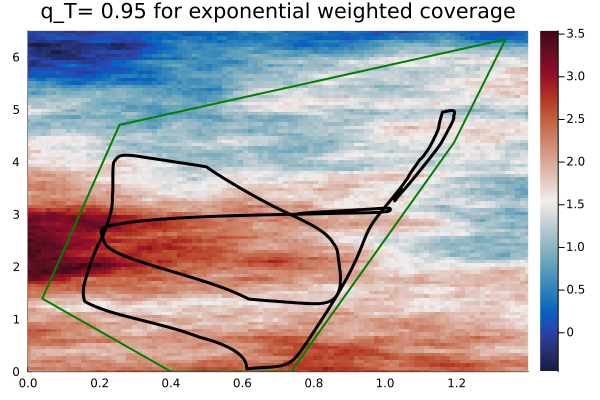

In [93]:
plot()
heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
polygon_vertices = hcat(convex_polygon.vertices, convex_polygon.vertices[:, 1])  # Close the polygon
plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
xlims!(0,1.4)
ylims!(0,6.5)
for i=1:length(x0s)
    x = [r[i][1] for r in res_ergo_exp.xs]
    
    y = [r[i][2] for r in res_ergo_exp.xs]
    plot!(x,y, linewidth=3, color=:black, label = "")
end
plot!()

title!("q_T= 0.95 for exponential weighted coverage")

┌ Info: Saved animation to
└ /home/dasc-group/KalebData/PhDResearch/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif


Plots.AnimatedGif("/home/dasc-group/Kaleb_Data/PhD_Research/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif")
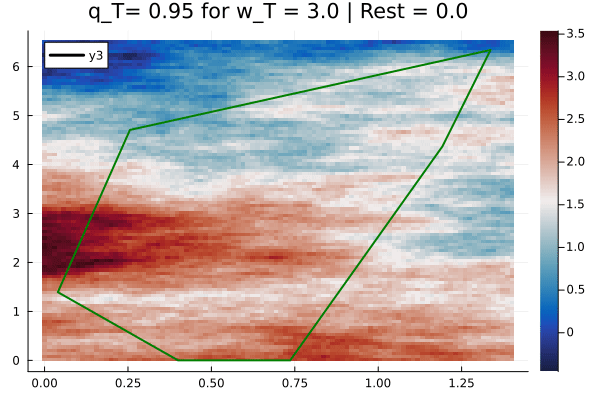

In [94]:
gr()
@gif for n = Int.(floor.(range(1, length(res_ergo_exp.xs), length=420)))
    plot()
    heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    for i=1:length(x0s)
        x = [r[i][1] for r in res_ergo_exp.xs[1:n]]
        y = [r[i][2] for r in res_ergo_exp.xs[1:n]]
        plot!(x, y, linewidth=3, color=:black)
    end
    plot!()
    title!("q_T= 0.95 for w_T = 3.0 | Rest = 0.0")
end

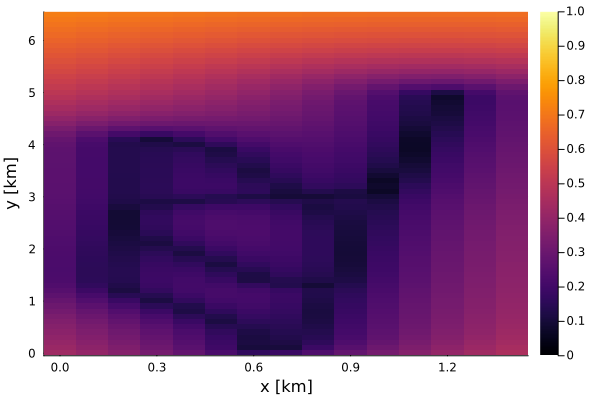

In [87]:
p2 = heatmap(ngpkf_grid, res_ergo_exp.w_hats[end], clims=(0, 1.0), plotstd=true)
# for i=1:length(x0s)
#     x = [r[i][1] for r in res_ergo.xs]
#     y = [r[i][2] for r in res_ergo.xs]
#     plot!(x, y, linewidth=3)
# end
plot!()

In [88]:
target_maps_exp = [res_ergo_exp.q_target_maps[1],]

for i=2:122:length(res_ergo_exp.q_target_maps)
    push!(target_maps_exp,res_ergo_exp.q_target_maps[i])
end

In [89]:
length(target_maps_exp)

61

In [90]:
length(res_ergo_exp.ergo_q_maps)

60

┌ Info: Saved animation to
└ /home/dasc-group/KalebData/PhDResearch/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif


Plots.AnimatedGif("/home/dasc-group/Kaleb_Data/PhD_Research/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif")
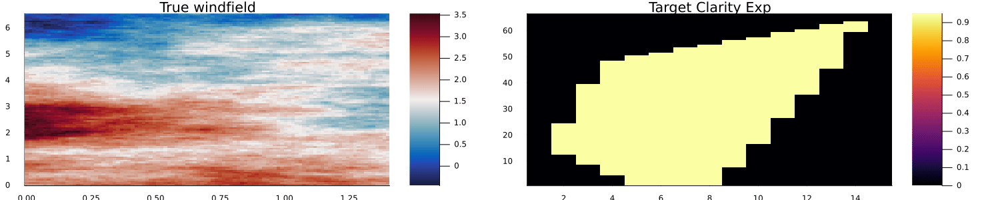

In [91]:
gr()
@gif for i=1:length(res_ergo_exp.ergo_q_maps)
    p0 = heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, title = "True windfield")
    p2 = heatmap(target_maps_exp[i]', title = "Target Clarity Exp")
    plot(p0, p2, layout=@layout[a c], size=(1500, 300))
#     title!("Weighted coverage")
end

┌ Info: Saved animation to
└ /home/dasc-group/KalebData/PhDResearch/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif


Plots.AnimatedGif("/home/dasc-group/Kaleb_Data/PhD_Research/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif")
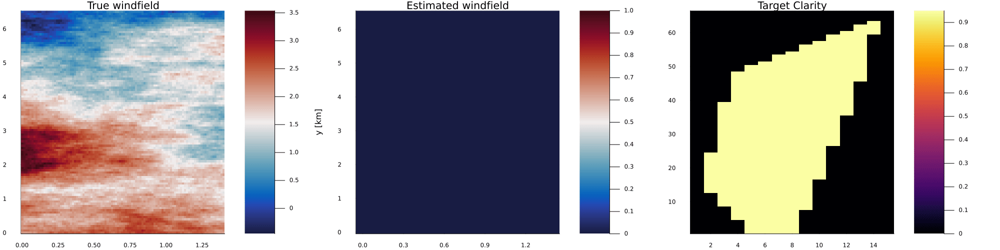

In [92]:
gr()
@gif for i=1:length(res_ergo_exp.ergo_q_maps)
    p0 = heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, title = "True windfield")
    p1 = heatmap(ngpkf_grid, res_ergo_exp.w_hats[i],colormap=:balance, title = "Estimated windfield")
    p3 = heatmap(target_maps_exp[i]', title = "Target Clarity")
    plot(p0, p1, p3, layout=@layout[a b c], size=(2000, 500))
#     title!("Weighted coverage")
end

In [80]:
# gr()
# @gif for i=1:length(res_ergo.ergo_q_maps)
#     p0 = heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, title = "True windfield")
#     p1 = heatmap(ngpkf_grid, res_ergo_exp.w_hats[i],colormap=:balance, title = "Estimated windfield")
#     p3 = heatmap(target_maps_exp[i]', title = "Target Clarity")
#     p2 = heatmap(res_ergo_exp.ergo_q_maps[i]', clims=(0, 1), title = "Clarity map")
#     plot(p0, p1, p2, p3, layout=@layout[a b c d], size=(2000, 350))
# #     title!("Weighted coverage")
# end

In [81]:
gr()
@gif for i=1:length(res_ergo_exp.q_target_maps)
    heatmap(res_ergo_exp.q_target_maps[i]', clims=(0, 1))
    title!("Target clarity map over time: iteration $i")
end

┌ Info: Saved animation to
└ /home/dasc-group/KalebData/PhDResearch/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif


Plots.AnimatedGif("/home/dasc-group/Kaleb_Data/PhD_Research/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif")

In [31]:
gr()

p1 = heatmap(ngpkf_grid, res_ergo.w_hats[end],colormap=:balance, clims=(-2,2), plot_min=true)
p2 = heatmap(ngpkf_grid, res_ergo.w_hats[end],colormap=:balance, clims=(-2,2), plot_max=true)
p3 = heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, clims=(-2, 2))
    
plot(p1, p3, p2, layout = (@layout [a;b; c]), size=[600, 600])

LoadError: UndefVarError: `res_ergo` not defined

In [32]:
# Compute RMSE

Nx, Ny = length(ngpkf_grid.xs), length(ngpkf_grid.ys)

M = reshape(KF.μ(res_ergo.w_hats[end]), Nx, Ny)
heatmap(M',colormap=:balance, clims=(-2,2) )
x_new = 0:0.4:25
y_new = 0:0.4:10
Data_sampled = [env_data.itp_w(xi, yi) for yi in y_new, xi in x_new]
Diff = M' .- Data_sampled
rmse = sqrt(mean(Diff .^ 2))

LoadError: UndefVarError: `res_ergo` not defined

In [33]:
M'

LoadError: UndefVarError: `M` not defined

In [34]:
heatmap(Data_sampled,colormap=:balance, clims=(-2,2))

LoadError: UndefVarError: `Data_sampled` not defined

In [35]:
# Compute Precision

σ_prec = KF.σ(res_ergo.w_hats[end])
M_prec = reshape(σ_prec, Nx, Ny)
precision = sum(M_prec)/length(M_prec)

LoadError: UndefVarError: `res_ergo` not defined

In [261]:
using LinearAlgebra, StatsBase

mean_deficit_1 = [mean(map( c -> max(0, 1.0 - c), q )) for q in res_ergo.ergo_q_maps]
mean_deficit_1[end]

0.20937851230359755

In [262]:
ts = range(1, 100, 20)
time = collect(ts)

20-element Vector{Float64}:
   1.0
   6.2105263157894735
  11.421052631578947
  16.63157894736842
  21.842105263157894
  27.05263157894737
  32.26315789473684
  37.473684210526315
  42.68421052631579
  47.89473684210526
  53.10526315789474
  58.31578947368421
  63.526315789473685
  68.73684210526316
  73.94736842105263
  79.15789473684211
  84.36842105263158
  89.57894736842105
  94.78947368421052
 100.0

In [263]:
# plot(res_ergo.w_hat_ts, mean_deficit_1, marker=:dot)
gr()
plot()
plot!(time, mean_deficit_1, marker=:dot)
ylabel!("Clarity Deficit[0,1]")
xlabel!("Time [min]")
ylims!(0., 0.6)

attempt to save state beyond implementation limit
attempt to save state beyond implementation limit


In [61]:
h2 = 25 - 1
ux_min = 1 * h2

24